In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sinter
import scipy

from memory_stats import combine_x_and_z

In [ ]:
stats = sinter.stats_from_csv_files('data.csv')

In [ ]:
def plot_linefit(ax, code_name, pers, lers):
    logx = np.log(pers)
    logy = np.log(lers)
    slope, intercept, _, _, _, = scipy.stats.linregress(
        logx, logy)
    ax.plot(np.exp(logx), np.exp(intercept + slope * logx),
            linestyle='--', color='orange')
    a = np.exp(intercept)

    b = slope

    if b != 1:
        x_cross = (1/a)**(1/(b-1))
        print(f"{code_name}: intersection at p = {x_cross:.12g}")

        ax.axvline(x=x_cross, color='r',
                   linestyle='--', alpha=0.5)
        ax.text(x_cross, x_cross,
                f'   $x =$ {x_cross:.2e}',
                rotation=90, verticalalignment='bottom',
                horizontalalignment='right', )
    return (x_cross)


def find_and_plot_crossing(ax, x_values, popt, fit_func,):
    try:
        root_result = scipy.optimize.root_scalar(
            lambda x: fit_func(x, *popt) - x,
            bracket=[min(x_values), max(x_values)]
        )
        if root_result.converged:
            print(f"Line crosses y=x at x = {root_result.root:.6f}")
            ax.axvline(x=root_result.root, color='r',
                       linestyle='--', alpha=0.5)
            ax.text(root_result.root, root_result.root,
                    f'   $x =$ {root_result.root:.2e}',
                    rotation=90, verticalalignment='bottom',
                    horizontalalignment='right', )
    except ValueError as e:
        print(f"Error finding crossing point: {e}")
    return root_result.root if root_result.converged else None


def plot_bb_30_4_5(ax, pers, factor, pseudothreshold: bool = True, label: str = None, color: str = 'blue'):
    # uses 35 qubits.
    c0 = 12.869
    c1 = -340.43
    c2 = 15878
    d = 5

    def fit_func(x, c0, c1, c2):
        return x**((d+1)/2) * np.e ** (c0 + c1 * x + c2 * x**2)*factor
    if label == None:
        label = str(factor) + ' rounds'
    ax.plot(pers, fit_func(pers, c0, c1, c2),
            label=label,
            color=color)
    if pseudothreshold:
        pseudo_threshold = find_and_plot_crossing(
            ax, pers, [c0, c1, c2], fit_func)
        return (pseudo_threshold)


def plot_bb_48_4_7(ax, pers, factor, pseudothreshold: bool = True, label: str = None, color: str = 'blue'):
    c0 = 18.256
    c1 = -260.44
    c2 = 680.65
    d = 7

    def fit_func(x, c0, c1, c2):
        return x**((d+1)/2) * np.e ** (c0 + c1 * x + c2 * x**2)*factor
    if label == None:
        label = str(factor) + ' rounds'

    ax.plot(pers, fit_func(pers, c0, c1, c2),
            label=label,
            color=color)
    if pseudothreshold:
        pseudo_threshold = find_and_plot_crossing(
            ax, pers, [c0, c1, c2], fit_func)
        return (pseudo_threshold)

In [ ]:
combined_stats = combine_x_and_z(stats)

In [ ]:
def group_by(items,
             key,
             ):

    result = {}

    for item in items:
        curve_id = key(item)
        result.setdefault(curve_id, []).append(item)

    return result


def plot_code(ax, code_name, x_min, x_max, pseudothreshold=True, color='blue', alpha=1, linestyle='', label=None):
    estimates_by_per = {}
    for estimate in combined_stats:
        if estimate.metadata['code'] == code_name:
            per = estimate.metadata['per']
            if per in estimates_by_per:
                raise ValueError(f"Multiple X/Z run configurations for {code_name} at p={per}")
            estimates_by_per[per] = estimate

    pers = np.array(sorted(estimates_by_per))
    full_lers = [estimates_by_per[per].error_rate for per in pers]
    full_errors = [estimates_by_per[per].standard_error for per in pers]
    ax.set_title(f"[{code_name.replace('_', ',')}]")

    # If no label provided, use the code name
    if label is None:
        label = f"[{code_name.replace('_', ',')}]"

    # Capture the handle from errorbar
    ax.errorbar(pers, full_lers, yerr=full_errors, fmt='o', color=color,
                ecolor=color, elinewidth=2, capsize=3, markersize=4, alpha=alpha, linestyle=linestyle, label=label)

    if pseudothreshold == True:
        filtered_pers = pers[(pers >= x_min) & (pers <= x_max)]

        filtered_lers = [estimates_by_per[per].error_rate for per in filtered_pers]
        return plot_linefit(ax, code_name, filtered_pers, filtered_lers)

In [ ]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (6, 8),
    "figure.dpi": 150,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "font.family": "serif",
    "lines.markersize": 10
})

In [ ]:
pseudothresholds = dict()

for code, n_qubits in zip(['30_4_5', '48_4_7', '7_1_3', '16_4_3', '18_6_3', '16_4_4', '27_9_3', '12_2_3', '20_4_4', '20_4_4_pauli'], [35, 54, 15, 35, 40, 38, 58, 28, 40, 40]):
    pseudothresholds[code] = dict()
    pseudothresholds[code]['n_qubits'] = n_qubits

In [ ]:

import matplotlib.pyplot as plt
x_min, x_max = 1e-4, 5e-2
fig, axes = plt.subplots(3, 4, figsize=(12.5, 10), sharey=True, sharex=True)
fig.tight_layout()


codes = [['7_1_3', '12_2_3', '16_4_3', '20_4_4'], [
    '18_6_3', '16_4_4', '27_9_3', '20_4_4_pauli']]
for i, code_row in enumerate(codes):
    for j, code in enumerate(code_row):
        pseudothresholds[code]['pseudo'] = plot_code(
            axes[i, j], code, x_min=0.0001, x_max=0.01)


pseudothresholds['30_4_5']['pseudo_d'] = plot_bb_30_4_5(
    axes[2, 0], pers=np.linspace(0.0001, 0.01, 100), factor=5, color='orange')

axes[2, 0].set_title('[30,4,5] BB5, five rounds')
pseudothresholds['30_4_5']['pseudo'] = plot_bb_30_4_5(
    axes[2, 1], pers=np.linspace(0.0001, 0.01, 100), factor=1, color='orange')
axes[2, 1].set_title('[30,4,5] BB5, one round')


pseudothresholds['48_4_7']['pseudo_d'] = plot_bb_48_4_7(
    axes[2, 2], pers=np.linspace(0.0001, 0.01, 100), factor=7, color='orange')
axes[2, 2].set_title("[48,4,7] BB5, seven rounds")
pseudothresholds['48_4_7']['pseudo'] = plot_bb_48_4_7(
    axes[2, 3], pers=np.linspace(0.0001, 0.01, 100), factor=1, color='orange')

axes[2, 3].set_title("[48,4,7] BB5, one round")

for ax in np.ravel(axes):
    ax.plot([x_min, x_max], [x_min, x_max], '--', color='gray')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(1e-6, 5e-1)
    ax.loglog()
    ax.grid()

for i in range(3):
    axes[i, 0].set_ylabel('Logical error rate per logical qubit', fontsize=12)

for j in range(4):
    axes[2, j].set_xlabel('Physical error rate', fontsize=12)
axes[1, 3].set_title('[20,4,4] pauli')

fig.tight_layout()
plt.show()
fig.savefig('color_code_pseudothresholds.pdf')

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(8, 12))


colors = ['red', 'blue', 'green', 'purple', 'orange', 'brown', 'black']

for i, code in enumerate(['16_4_4', '20_4_4', '20_4_4_pauli']):

    plot_code(
        ax[0], code, x_min=0.0001, x_max=0.01, pseudothreshold=False, color='grey', alpha=0.25, linestyle='-')


for i, code in enumerate(['7_1_3', '12_2_3', '16_4_3', '18_6_3', '27_9_3']):

    plot_code(
        ax[0], code, x_min=0.0001, x_max=0.01, pseudothreshold=False, color=colors[i], linestyle='-')

    plot_code(
        ax[1], code, x_min=0.0001, x_max=0.01, pseudothreshold=False, color='grey', linestyle='-', alpha=0.25)

for i, code in enumerate(['16_4_4', '20_4_4', '20_4_4_pauli']):

    plot_code(
        ax[1], code, x_min=0.0001, x_max=0.01, pseudothreshold=False, color=colors[i], linestyle='-')

x_min = 0.0001
x_max = 0.01
for axes in ax:
    axes.plot([x_min, x_max], [x_min, x_max],
              '--', color='gray', label='$y=x$')

    axes.loglog()

    axes.set_xlim(0.0001, 0.01)
    axes.set_ylim(1e-7, 0.05)
    axes.grid()
    axes.set_ylabel('Logical error rate per logical qubit', fontsize=12)

handles, labels = ax[0].get_legend_handles_labels()
handles.append(handles[2])
labels.append('d=4 codes')
ax[0].legend(handles[4:], labels[4:], loc='lower right')


handles, labels = ax[1].get_legend_handles_labels()
handles.append(handles[2])
labels.append('d=3 codes')
labels[-2] = '[20,4,4] pauli'
ax[1].legend(handles[6:], labels[6:], loc='lower right')


ax[0].set_title('Distance 3 codes', fontsize=16)
ax[1].set_title('Distance 4 codes', fontsize=16)

ax[1].set_xlabel('Physical error rate', fontsize=12)

fig.savefig('d_3_d_4_plot.pdf')

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(8, 12))


for index, round_factor in enumerate([5, 1]):
    plot_bb_30_4_5(
        ax[index], pers=np.linspace(0.0001, 0.01, 100), factor=round_factor, pseudothreshold=False, label='[30,4,5] BB5 code', color='#2A9D8F')

for index, round_factor in enumerate([7, 1]):
    plot_bb_48_4_7(
        ax[index], pers=np.linspace(0.0001, 0.01, 100), factor=round_factor, pseudothreshold=False, label='[48,4,7] BB5 code', color='#E9C46A')


for axes in ax:
    for index, code in enumerate(['16_4_4']):
        plot_code(
            axes, code, x_min=0.0001, x_max=0.01, pseudothreshold=False, color='red', linestyle='-')


x_min = 0.0001
x_max = 0.01
for axes in ax:
    axes.plot([x_min, x_max], [x_min, x_max],
              '--', color='gray', label='$y=x$')

for axes in ax:
    axes.loglog()
    axes.legend()
    axes.set_xlim(0.0001, 0.01)
    axes.grid()
ax[0].set_title(r'Steane EC vs Shor EC', fontsize=16)
ax[1].set_title(r'Steane EC vs one round of syndrome extraction', fontsize=16)

ax[1].set_xlabel('Physical error rate', fontsize=12)
ax[1].set_ylabel('Logical error rate per logical qubit', fontsize=12)
ax[0].set_ylabel('Logical error rate per logical qubit', fontsize=12)
fig.savefig('color_code_vs_BB5.pdf')

In [ ]:
fig2, ax2 = plt.subplots(figsize=(5, 8))

for code, data in pseudothresholds.items():
    if code == '30_4_5' or code == '48_4_7':
        continue
    if 'pseudo' in data and data['pseudo'] is not None:
        ax2.plot(data['n_qubits'],
                 100*(1-data['pseudo']), 'o', label=code, color='black', markersize=8)

ax2.set_ylabel(
    'Breakeven two-qubit gate fidelity (%), lower is better', fontsize=12)
ax2.set_xlabel('Data + ancilla qubits', fontsize=12)
ax2.grid()
ax2.yaxis.set_major_formatter(plt.ScalarFormatter(useMathText=True))
ax2.set_xlim(0, 65)

fig2.savefig("breakeven_two-qubit_gate_fidelity.svg")

In [ ]:
fig2, ax2 = plt.subplots(figsize=(5, 8))

for code, data in pseudothresholds.items():
    if 'pseudo' in data and data['pseudo'] is not None:
        ax2.plot(data['n_qubits'],
                 100*(1-data['pseudo']), 'o', label=code)
        ax2.text(data['n_qubits'], 100*(1-data['pseudo']), '[' + code.replace('_', ',') + ']',
                 fontsize=10, horizontalalignment='right')

ax2.set_ylabel(
    'Breakeven two-qubit gate fidelity (%), lower is better', fontsize=14)
ax2.set_xlabel('Total number of qubits')
ax2.grid()
ax2.legend()

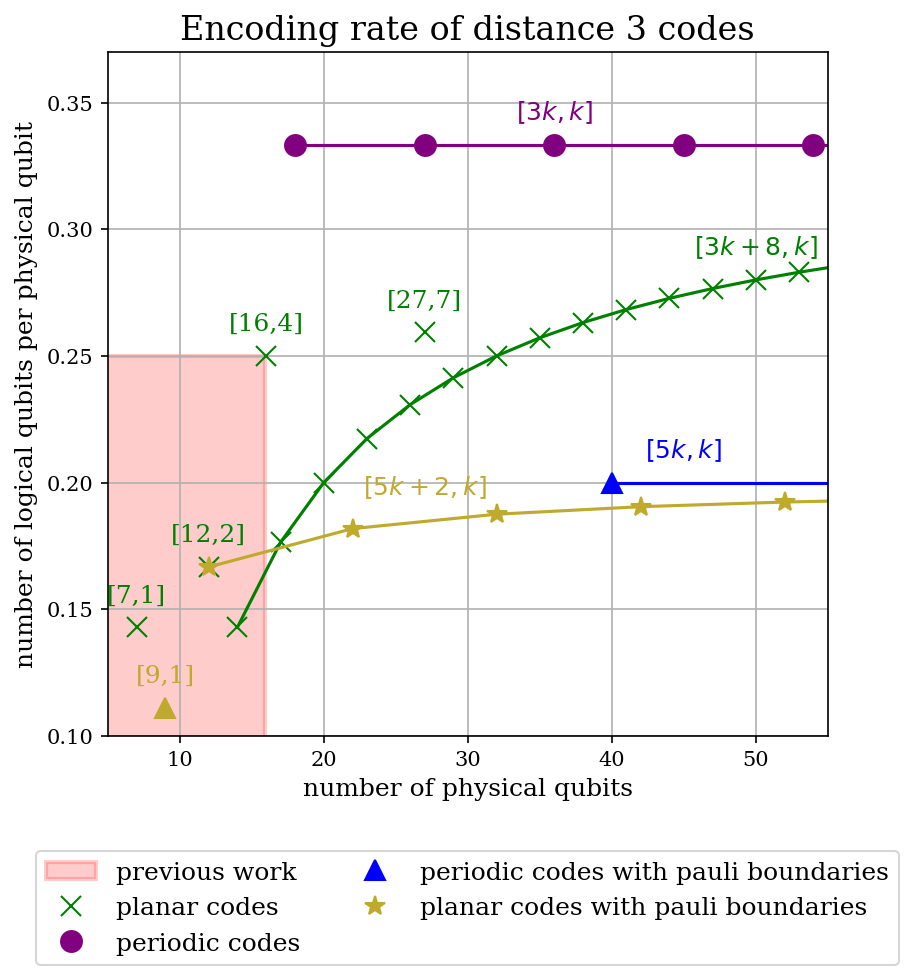

In [ ]:
def plot_code_stat(n, k, m_color='black', symbol='o'):
    plt.plot(n, k/n, symbol, color=m_color)
    plt.text(n, k/n+0.01, '['+str(n)+','+str(k)+']',
             ha='center', color=m_color, fontsize=12)


# planar codes
plt.plot([3*k+8 for k in range(2, 20, 1)],
         [k/(3*k+8) for k in range(2, 20, 1)], '-x', color='green')
plt.text(3*14+8, 14/(3*14+8)+0.01,
         r'$\left[3k+8, k\right]$',  ha='center', color='green', fontsize=12)
plot_code_stat(7, 1, 'green', 'x')
plot_code_stat(12, 2, 'green', 'x')
plot_code_stat(16, 4, 'green', 'x')
plot_code_stat(27, 7, 'green', 'x')

# periodic codes
plt.plot([3*k for k in range(6, 25, 3)],
         [k/(3*k) for k in range(6, 25, 3)], '-o', color='purple',)
plt.text(3*12, 12/(3*12)+0.01,
         r'$\left[3k,k\right]$',  ha='center', color='purple', fontsize=12)


# planar pauli codes
yellow = "#c0aa2d"
plot_code_stat(9, 1, yellow, '^')
plt.plot([5*k+2 for k in range(2, 15, 2)], [k/(5*k+2)
         for k in range(2, 15, 2)], '-*', color=yellow, )
plt.text(5*5+2, 5/(5*5+2)+0.01,
         r'$\left[5k+2,k\right]$',  ha='center', color=yellow, fontsize=12)

# periodic pauli codes
yellow = "#c0aa2d"
plt.plot([5*k for k in range(8, 17, 8)], [k/(5*k)
         for k in range(8, 17, 8)], '-^', color='blue')
plt.text(5*9, 9/(5*9)+0.01,
         r'$\left[5k,k\right]$', ha='center', color='blue', fontsize=12)


rect = patches.Rectangle((-0.1, 0), 16, 0.25, linewidth=2,
                         edgecolor='red', alpha=0.2, facecolor='red', label='previous work')
plt.gca().add_patch(rect)

plt.plot([], [], 'x', color='green', label='planar codes')
plt.plot([], [], 'o', color='purple', label='periodic codes')
plt.plot([], [], '^', color='blue',
         label='periodic codes with pauli boundaries')
plt.plot([], [], '*', color=yellow,
         label='planar codes with pauli boundaries')
plt.title('Encoding rate of distance 3 codes', fontsize=16)
plt.ylim(0.1, 0.37)
plt.xlim(5, 55)
plt.legend(loc='upper center', bbox_to_anchor=(
    0.5, -0.15), ncol=2, frameon=True, fancybox=True, fontsize=12)
plt.grid()
plt.xlabel('number of physical qubits', fontsize=12)
plt.ylabel('number of logical qubits per physical qubit', fontsize=12)

plt.subplots_adjust(left=0.12, right=0.92, top=0.92, bottom=0.35)

# plt.show()
plt.savefig('d_3_code_overview_plot.pdf')

# there's a mistake in the legend

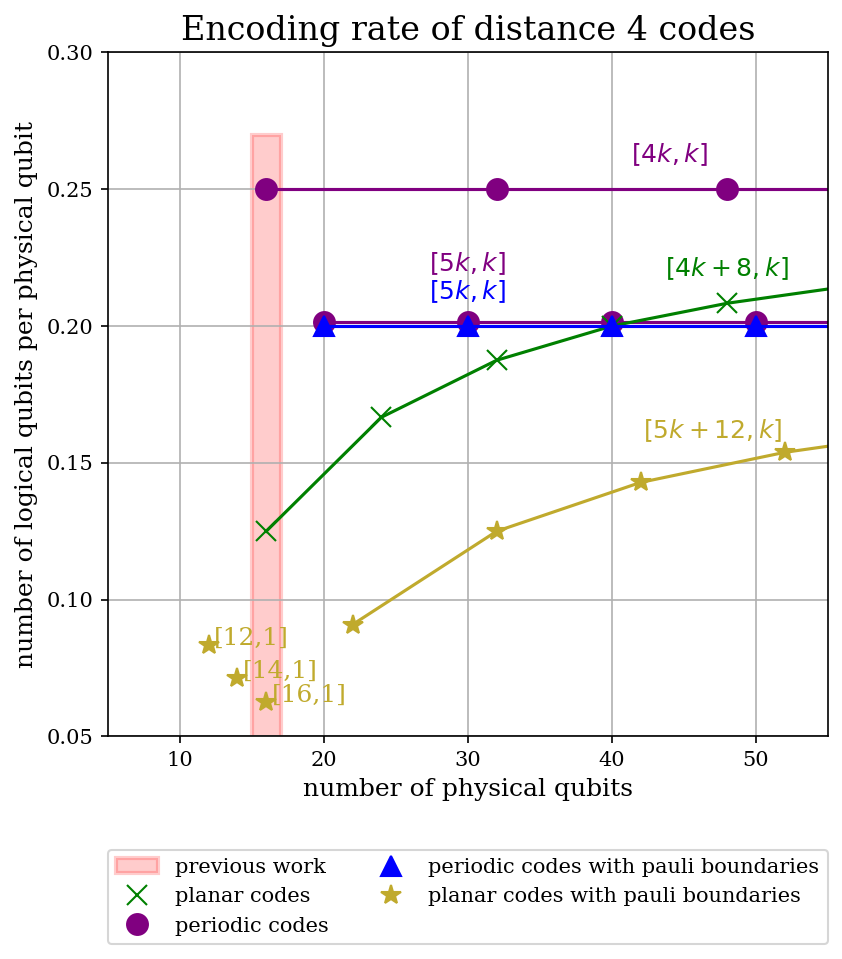

In [ ]:
max_n = 55
min_n = 5
range_n = range(min_n, max_n)


def plot_code_stat(n, k, m_color='black', symbol='o'):
    plt.plot(n, k/n, symbol, color=m_color)
    plt.text(n+3, k/n, '['+str(n)+','+str(k)+']',
             ha='center', color=m_color, fontsize=12)


# periodic codes
plt.plot([4*k for k in range(4, 30, 4)],
         [k/(4*k) for k in range(4, 30, 4)], '-o', color='purple')
plt.text(4*11, 11/(4*11)+0.01,
         r'$\left[4k,k\right]$', ha='center', color='purple', fontsize=12)

plt.plot([5*k for k in range(4, 15, 2)],
         [k/(5*k)+0.0015 for k in range(4, 15, 2)], '-o', color='purple')
plt.text(5*6, 6/(5*6)+0.02,
         r'$\left[5k,k\right]$', ha='center', color='purple', fontsize=12)


# planar codes
plt.plot([4*k + 8 for k in range(2, 13, 2)],
         [k/(4*k+8) for k in range(2, 13, 2)], '-x', color='green')
plt.text(4*10+8, 10/(4*10+8)+0.01,
         r'$\left[4k+8,k\right]$', ha='center', color='green', fontsize=12)


# planar codes with pauli boundaries
yellow = "#c0aa2d"

plt.plot([5*k + 12 for k in range(2, 15, 2)],
         [k/(5*k+12) for k in range(2, 15, 2)], '-*', color=yellow)
plt.text(5*7+12, 7/(5*7+12)+0.01,
         r'$\left[5k+12,k\right]$', ha='center', color=yellow, fontsize=12)

# periodic codes with pauli boundaries
plt.plot([5*k for k in range(4, 15, 2)],
         [k/(5*k) for k in range(4, 15, 2)], '-^', color='blue')
plt.text(5*6, 6/(5*6)+0.01,
         r'$\left[5k,k\right]$', ha='center', color='blue', fontsize=12)

plot_code_stat(14, 1, m_color=yellow, symbol='*')
plot_code_stat(12, 1, m_color=yellow, symbol='*')
plot_code_stat(16, 1, m_color=yellow, symbol='*')

rect = patches.Rectangle((15, 0), 2, 0.27, linewidth=2,
                         edgecolor='red', alpha=0.2, facecolor='red', label='previous work')

plt.gca().add_patch(rect)

plt.title('Encoding rate of distance 4 codes', fontsize=16)
plt.plot([], [], 'x', color='green', label='planar codes')
plt.plot([], [], 'o', color='purple', label='periodic codes')
plt.plot([], [], '^', color='blue',
         label='periodic codes with pauli boundaries')
plt.plot([], [], '*', color=yellow,
         label='planar codes with pauli boundaries')

plt.grid()
plt.ylim(0.05, 0.3)
plt.xlim(5, 55)
plt.legend(loc='upper center', bbox_to_anchor=(
    0.5, -0.15), ncol=2, frameon=True, fancybox=True)

plt.xlabel('number of physical qubits', fontsize=12)
plt.ylabel('number of logical qubits per physical qubit', fontsize=12)
plt.subplots_adjust(left=0.12, right=0.92, top=0.92, bottom=0.35)
plt.savefig('d_4_code_overview_plot.pdf')

In [ ]:

from small_color_codes.code_library import get_noiseless_circuits
import stim
import numpy as np


def stim_circ_statistics(circ: stim.Circuit):
    """Prints the number of qubits, measurements, and ticks in a stim circuit."""

    gates = {}
    for op in circ:
        if op.name not in gates:

            gates[op.name] = len(op.target_groups())
        else:
            gates[op.name] += len(op.target_groups())

    statistics = {
        "num_cnot": gates["CX"],
        "num_H": gates["H"],
        "num_prep": gates["R"],
        "num_meas": gates["M"],
        "num_qubits": circ.num_qubits,
        "num_measurements": circ.num_measurements,
        "num_ticks": circ.num_ticks,
        "gates": gates
    }
    return statistics


def get_steane_ec_circuit_statistics(code):
    noiseless_circuits = get_noiseless_circuits(code, basis='Z')
    circ = stim.Circuit()
    circ += noiseless_circuits.ancilla_logical_plus_init
    circ += noiseless_circuits.steane_ec_z_stabilizers
    circ += noiseless_circuits.ancilla_logical_0_init
    circ += noiseless_circuits.steane_ec_x_stabilizers
    statistics = stim_circ_statistics(circ)
    return statistics


codes = ["7_1_3", "12_2_3", "16_4_3", "18_6_3",
         "27_9_3", "16_4_4", "20_4_4", "20_4_4_pauli"]
statistics = dict()
for code in codes:
    statistics[code] = get_steane_ec_circuit_statistics(code)

In [ ]:
def circuit_statistics(n_qubits, n_x_stabilizers, n_z_stabilizers, stabilizer_weight, n_readouts_in_parallel):
    statistics = dict()
    statistics['num_qubits'] = n_qubits
    statistics['num_H'] = 2*(n_x_stabilizers + n_z_stabilizers)
    statistics['num_cnot'] = stabilizer_weight * \
        (n_x_stabilizers + n_z_stabilizers)
    statistics['num_meas'] = n_x_stabilizers + n_z_stabilizers
    statistics['num_prep'] = n_x_stabilizers + n_z_stabilizers
    statistics['num_ticks'] = int((statistics['num_H'] + statistics['num_cnot'] +
                                   statistics['num_meas'] / n_readouts_in_parallel +
                                   statistics['num_prep'] / n_readouts_in_parallel))
    return statistics


statistics['30_4_5'] = circuit_statistics(n_qubits=35, n_x_stabilizers=15, n_z_stabilizers=15,
                                          stabilizer_weight=5, n_readouts_in_parallel=5)


statistics['48_4_7'] = circuit_statistics(n_qubits=56, n_x_stabilizers=24, n_z_stabilizers=24,
                                          stabilizer_weight=5, n_readouts_in_parallel=6)

In [ ]:
def write_code_row(f, code, label=None, depth_multiplier=None):
    """Write a single code row to the LaTeX table.

    Args:
        f: File handle
        code: Code name (e.g., '30_4_5')
        label: Custom label (optional, defaults to code name)
        depth_multiplier: If provided, multiplies depth and gate counts by this factor
    """
    code_label = label if label else f"${code.replace('_', ',')}$"
    stats = statistics[code]

    # Apply depth multiplier to all relevant statistics
    if depth_multiplier:
        depth = stats['num_ticks'] * depth_multiplier
        num_cnot = stats['num_cnot'] * depth_multiplier
        num_H = stats['num_H'] * depth_multiplier
        num_meas = stats['num_meas'] * depth_multiplier
        num_prep = stats['num_prep'] * depth_multiplier
        pseudo = pseudothresholds[code]['pseudo_d']

    else:
        depth = stats['num_ticks']
        num_cnot = stats['num_cnot']
        num_H = stats['num_H']
        num_meas = stats['num_meas']
        num_prep = stats['num_prep']
        pseudo = pseudothresholds[code]['pseudo']

    f.write(
        f"{code_label} & {stats['num_qubits']} & {depth} & "
        f"{num_cnot} & {num_H} & {num_meas} & "
        f"{num_prep} & {pseudo:.2e} \\\\\n"
    )
    f.write("\\hline\n")


def write_section_header(f, title):
    """Write a section header spanning all columns."""
    f.write(f"\\multicolumn{{8}}{{|c|}}{{\\textbf{{{title}}}}} \\\\ \\hline\n")


with open("code_table.tex", "w") as f:
    # Table header
    f.write("\\begin{tabular}{|c|c|c|c|c|c|c|c|}\n")
    f.write("\\hline\n")
    f.write("n, k, d & Qubits & Depth & 2Q Gates & 1Q Gates & Meas. & Reset & Pseudoth. \\\\ \\hline\n")

    # Distance-3 color codes
    write_section_header(f, "Steane style EC with distance-3 color codes")
    for code in codes[0:5]:
        write_code_row(f, code)

    # Distance-4 color codes
    write_section_header(f, "Steane style EC with distance-4 color codes")
    for code in codes[5:7]:
        write_code_row(f, code)

    # Distance-4 with Pauli boundaries
    write_code_row(f, "20_4_4_pauli", label="$20,4,4$ pauli")

    # Bivariate bicycle codes with full EC (d rounds)
    write_section_header(f, "Shor style EC with bivariate bicycle codes")
    for code in ['30_4_5', '48_4_7']:
        d = int(code[-1])
        write_code_row(f, code, depth_multiplier=d)

    # One round of syndrome extraction
    write_section_header(
        f, "One round of Shor style syndrome extraction with bivariate bicycle codes")
    for code in ['30_4_5', '48_4_7']:
        write_code_row(f, code)

    f.write("\\end{tabular}\n")

# Display the generated table
with open("code_table.tex", "r") as f:
    print(f.read())

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

# Extract depth and pseudothreshold for each code
depths = []
pseudos = []
labels = []

for code in pseudothresholds.keys():
    # Skip bivariate bicycle codes
    if code in ['30_4_5', '48_4_7']:
        continue
    if code in statistics and 'pseudo' in pseudothresholds[code] and pseudothresholds[code]['pseudo'] is not None:
        depths.append(statistics[code]['num_ticks'])
        pseudos.append(pseudothresholds[code]['pseudo'])
        # Special formatting for pauli variant
        if code == '20_4_4_pauli':
            labels.append('[20,4,4] pauli')
        else:
            labels.append('[' + code.replace('_', ',') + ']')

# Create scatter plot
ax.scatter(depths, pseudos, s=100, alpha=0.7, color='blue')

# Add labels for each point
for i, label in enumerate(labels):
    # Place [27,9,3] label to the left of the marker
    if label == '[27,9,3]':
        ax.annotate(label, (depths[i], pseudos[i]),
                    xytext=(-5, 5), textcoords='offset points',
                    fontsize=10, alpha=0.8, horizontalalignment='right')
    else:
        ax.annotate(label, (depths[i], pseudos[i]),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=10, alpha=0.8)

ax.set_xlabel('Circuit depth', fontsize=12)
ax.set_ylabel('Pseudothreshold', fontsize=12)
ax.yaxis.set_major_formatter(plt.ScalarFormatter(useMathText=True))
ax.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('pseudothreshold_vs_depth.pdf')
plt.show()